In [ ]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import random

from src.data.database import EntityDatabase
from src.embeddings import TextEmbedder, save_embeddings, load_cached_embeddings, get_embedding_cache_info
from src.embeddings import reduce_embeddings_for_visualization

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## 1. Load Selected Entities

In [25]:
# Load selected entities
entities_file = Path('../data/experiment/selected_entities.csv')
df = pd.read_csv(entities_file)

print(f"✓ Loaded {len(df)} entities")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst 3 entities:")
print(df[['id', 'label', 'wikidata_id', 'culture', 'country']].head(3))

✓ Loaded 26098 entities

Columns: ['id', 'wikidata_id', 'type', 'culture', 'country', 'created_at', 'label', 'labels']

First 3 entities:
   id           label wikidata_id  culture        country
0   1  Dwayne Johnson      Q10738  Western  United States
1   2      Mick Foley      Q10731  Western  United States
2   3    Bill Clinton       Q1124  Western  United States


## 2. Connect to Database & Extract Wikipedia Texts

In [26]:
db_path = Path('../data/entities.db')
db = EntityDatabase(db_path)

print(f"✓ Connected to database: {db_path}")

✓ Connected to database: ../data/entities.db


In [57]:
wiki_texts = db.get_wikipedia_texts(1)
len(wiki_texts.get('en').get('summary'))

3440

In [56]:
len(wiki_texts.get('en').get('content'))

71533

In [27]:
# Extract Wikipedia texts for each language
languages = ['en', 'fr', 'ar']
entity_ids = df['id'].tolist()

# Choose: 'summary' or 'content'
text_type = 'summary'  # Change to 'content' for full text (will be truncated at 512 tokens!)

wikipedia_data = {lang: {'entity_ids': [], 'texts': []} for lang in languages}

print(f"Extracting Wikipedia texts ({text_type})...")
for entity_id in tqdm(entity_ids, desc="Processing entities"):
    wiki_texts = db.get_wikipedia_texts(entity_id)

    for lang in languages:
        if lang in wiki_texts and wiki_texts[lang][text_type]:
            wikipedia_data[lang]['entity_ids'].append(entity_id)
            wikipedia_data[lang]['texts'].append(wiki_texts[lang][text_type])

# Show statistics
print("\n" + "="*60)
for lang in languages:
    texts = wikipedia_data[lang]['texts']
    word_counts = [len(text.split()) for text in texts]
    print(f"{lang.upper()}: {len(texts)} texts")
    print(f"  Avg length: {np.mean(word_counts):.0f} words")
    print(f"  Max length: {max(word_counts)} words")
    print(f"  Min length: {min(word_counts)} words")
print("="*60)

# Warning if using full content
if text_type == 'content':
    max_tokens = 512
    print(f"\n⚠️  WARNING: Model max context = {max_tokens} tokens (~384 words)")
    print(f"   Long texts will be truncated. Consider using 'summary' instead.")

Extracting Wikipedia texts (summary)...


Processing entities:   0%|          | 0/26098 [00:00<?, ?it/s]


EN: 26098 texts
  Avg length: 104 words
  Max length: 971 words
  Min length: 1 words
FR: 26095 texts
  Avg length: 74 words
  Max length: 1170 words
  Min length: 6 words
AR: 26074 texts
  Avg length: 58 words
  Max length: 3416 words
  Min length: 2 words


## 3. Check for Cached Embeddings

In [31]:
cache_dir = Path('../data/embeddings')
cache_dir.mkdir(parents=True, exist_ok=True)

# Check what's already cached
cached_files = get_embedding_cache_info(cache_dir)

if cached_files:
    print(f"Found {len(cached_files)} cached embedding files:")
    for cache_info in cached_files:
        print(f"\n  File: {cache_info['filename']}")
        print(f"  Language: {cache_info['language']}")
        print(f"  Model: {cache_info['model_name']}")
        print(f"  Count: {cache_info['num_entities']}")
        print(f"  Shape: {cache_info['shape']}")
else:
    print("No cached embeddings found")

Found 3 cached embedding files:

  File: embeddings_ar_intfloat_multilingual-e5-large.pkl
  Language: ar
  Model: intfloat/multilingual-e5-large
  Count: 26074
  Shape: (26074, 1024)

  File: embeddings_en_intfloat_multilingual-e5-large.pkl
  Language: en
  Model: intfloat/multilingual-e5-large
  Count: 26098
  Shape: (26098, 1024)

  File: embeddings_fr_intfloat_multilingual-e5-large.pkl
  Language: fr
  Model: intfloat/multilingual-e5-large
  Count: 26095
  Shape: (26095, 1024)


## 4. Generate or Load Embeddings

Using model: `intfloat/multilingual-e5-large` (max 512 tokens)

In [32]:
model_name = 'intfloat/multilingual-e5-large'
embeddings = {}

print(f"Model: {model_name}\n")
print("="*60)

for lang in languages:
    print(f"\nProcessing {lang.upper()}...")

    # Try to load cached embeddings
    cached = load_cached_embeddings(
        language=lang,
        model_name=model_name,
        save_dir=cache_dir
    )

    if cached is not None:
        print(f"  ✓ Loaded from cache")
        embeddings[lang] = {
            'embeddings': cached['embeddings'],
            'entity_ids': cached['entity_ids'],
            'model_name': cached['model_name']
        }
        print(f"  Shape: {cached['embeddings'].shape}")
    else:
        print(f"  Generating embeddings...")

        # Initialize embedder (only when needed)
        if 'embedder' not in locals():
            print(f"  Loading model: {model_name}")
            embedder = TextEmbedder(model_name)
            embedder.load_model()

        # Generate embeddings
        texts = wikipedia_data[lang]['texts']
        emb = embedder.embed_texts(texts, batch_size=32, show_progress=True)

        # Save to cache
        save_embeddings(
            embeddings=emb,
            entity_ids=wikipedia_data[lang]['entity_ids'],
            language=lang,
            model_name=model_name,
            save_dir=cache_dir,
            metadata={'num_texts': len(texts)}
        )

        embeddings[lang] = {
            'embeddings': emb,
            'entity_ids': wikipedia_data[lang]['entity_ids'],
            'model_name': model_name
        }
        print(f"  ✓ Generated and cached")
        print(f"  Shape: {emb.shape}")

print("\n" + "="*60)
print("EMBEDDINGS READY")
print("="*60)

Model: intfloat/multilingual-e5-large


Processing EN...
  ✓ Loaded from cache
  Shape: (26098, 1024)

Processing FR...
  ✓ Loaded from cache
  Shape: (26095, 1024)

Processing AR...
  ✓ Loaded from cache
  Shape: (26074, 1024)

EMBEDDINGS READY


## 5. Validate Embeddings

In [33]:
# Check embedding properties
print("Embedding Validation:\n")

for lang in languages:
    emb = embeddings[lang]['embeddings']

    print(f"{lang.upper()}:")
    print(f"  Shape: {emb.shape}")
    print(f"  Dtype: {emb.dtype}")
    print(f"  Mean: {emb.mean():.4f}")
    print(f"  Std: {emb.std():.4f}")
    print(f"  Min: {emb.min():.4f}")
    print(f"  Max: {emb.max():.4f}")

    # Check for NaN or Inf
    has_nan = np.isnan(emb).any()
    has_inf = np.isinf(emb).any()
    print(f"  Has NaN: {has_nan}")
    print(f"  Has Inf: {has_inf}")
    print()

Embedding Validation:

EN:
  Shape: (26098, 1024)
  Dtype: float32
  Mean: -0.0008
  Std: 0.0312
  Min: -0.1299
  Max: 0.2440
  Has NaN: False
  Has Inf: False

FR:
  Shape: (26095, 1024)
  Dtype: float32
  Mean: -0.0008
  Std: 0.0312
  Min: -0.1345
  Max: 0.2438
  Has NaN: False
  Has Inf: False

AR:
  Shape: (26074, 1024)
  Dtype: float32
  Mean: -0.0008
  Std: 0.0312
  Min: -0.1359
  Max: 0.2352
  Has NaN: False
  Has Inf: False



In [34]:
# Compute norms
for lang in languages:
    emb = embeddings[lang]['embeddings']
    norms = np.linalg.norm(emb, axis=1)

    print(f"{lang.upper()} - L2 Norms:")
    print(f"  Mean: {norms.mean():.4f}")
    print(f"  Std: {norms.std():.4f}")
    print(f"  Min: {norms.min():.4f}")
    print(f"  Max: {norms.max():.4f}")
    print()

EN - L2 Norms:
  Mean: 1.0000
  Std: 0.0000
  Min: 1.0000
  Max: 1.0000

FR - L2 Norms:
  Mean: 1.0000
  Std: 0.0000
  Min: 1.0000
  Max: 1.0000

AR - L2 Norms:
  Mean: 1.0000
  Std: 0.0000
  Min: 1.0000
  Max: 1.0000



## 6. Visualize Embedding Space (2D)

In [35]:
# Reduce to 2D for visualization
embeddings_2d = {}

print("Reducing embeddings to 2D (UMAP)...")
for lang in languages:
    emb = embeddings[lang]['embeddings']
    emb_2d = reduce_embeddings_for_visualization(emb, method='umap')
    embeddings_2d[lang] = emb_2d
    print(f"  {lang.upper()}: {emb.shape} -> {emb_2d.shape}")

Reducing embeddings to 2D (UMAP)...


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  EN: (26098, 1024) -> (26098, 2)


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  FR: (26095, 1024) -> (26095, 2)


/home/khaledbouabdallah/Projects/llm_grouping_loss_INRIA/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


  AR: (26074, 1024) -> (26074, 2)


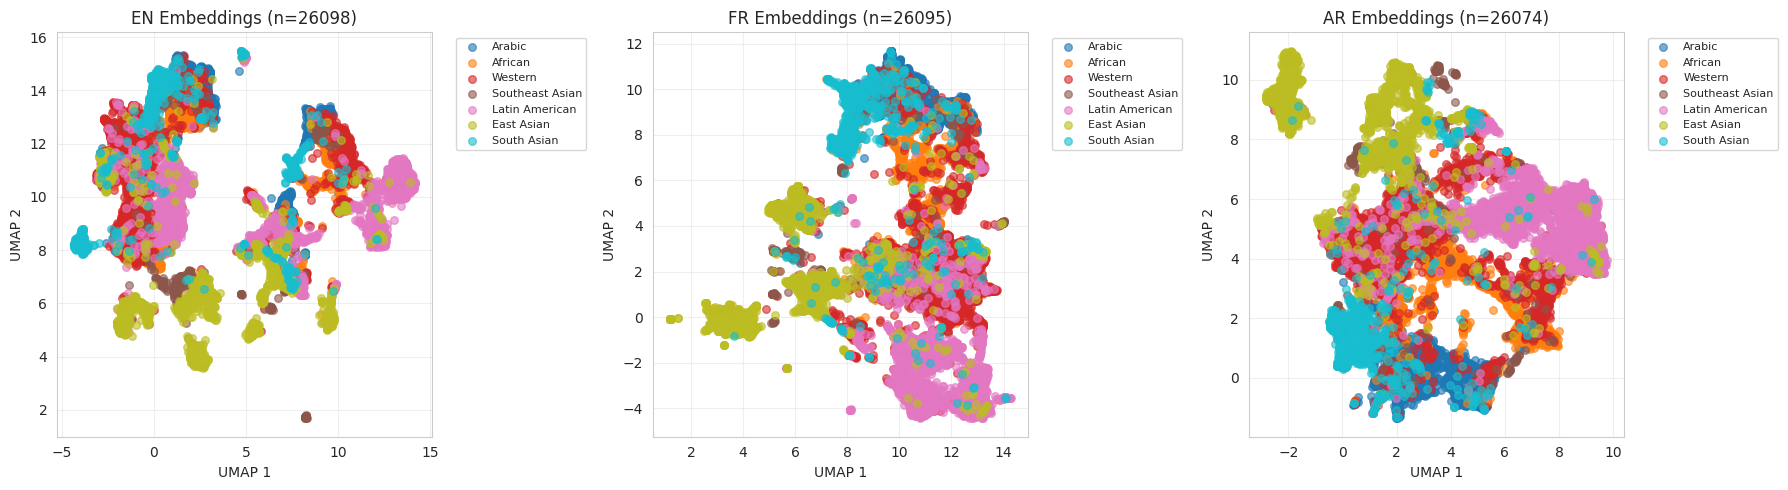

In [36]:
# Plot 2D embeddings for each language
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to culture
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    cultures = [entity_df.loc[eid, 'culture'] if eid in entity_df.index else 'Unknown'
                for eid in entity_ids]

    # Plot with culture colors
    unique_cultures = list(set(cultures))
    colors = plt.cm.tab10(np.linspace(0, 1, len(unique_cultures)))

    for culture, color in zip(unique_cultures, colors):
        mask = np.array([c == culture for c in cultures])
        ax.scatter(emb_2d[mask, 0], emb_2d[mask, 1],
                  c=[color], label=culture, alpha=0.6, s=30)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

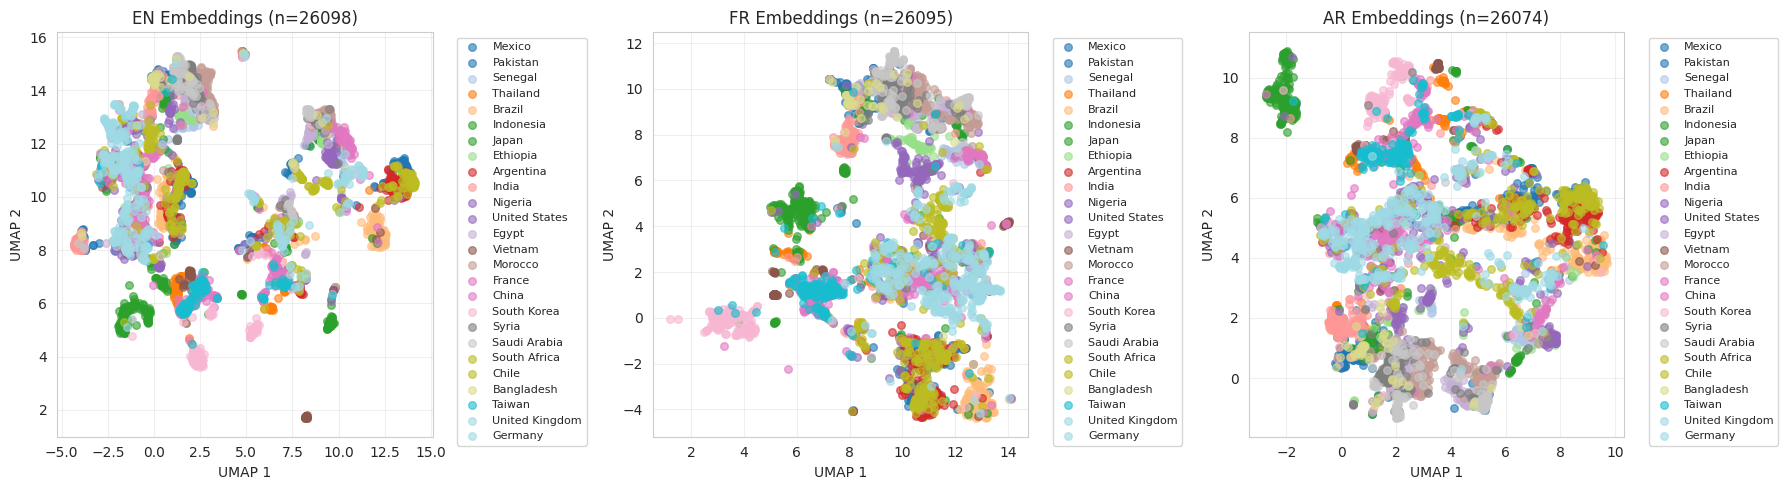

In [ ]:


# Plot 2D embeddings for each language
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, lang in enumerate(languages):
    ax = axes[i]
    emb_2d = embeddings_2d[lang]

    # Get entity IDs and map to country
    entity_ids = embeddings[lang]['entity_ids']
    entity_df = df[df['id'].isin(entity_ids)].set_index('id')
    countries = [entity_df.loc[eid, 'country'] if eid in entity_df.index else 'Unknown'
                 for eid in entity_ids]

    # Unique countries and assign colors
    unique_countries = list(set(countries))
    colors = plt.cm.tab20(np.linspace(0, 1, len(unique_countries)))

    for country, color in zip(unique_countries, colors):
        mask = np.array([c == country for c in countries])
        indices = np.where(mask)[0]

        # Sample up to 200 per country
        if len(indices) > 200:
            indices = random.sample(list(indices), 200)

        ax.scatter(emb_2d[indices, 0], emb_2d[indices, 1],
                   c=[color], label=country, alpha=0.6, s=30)

    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.set_title(f'{lang.upper()} Embeddings (n={len(emb_2d)})')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Compare Languages

Plot all languages together to see if they cluster

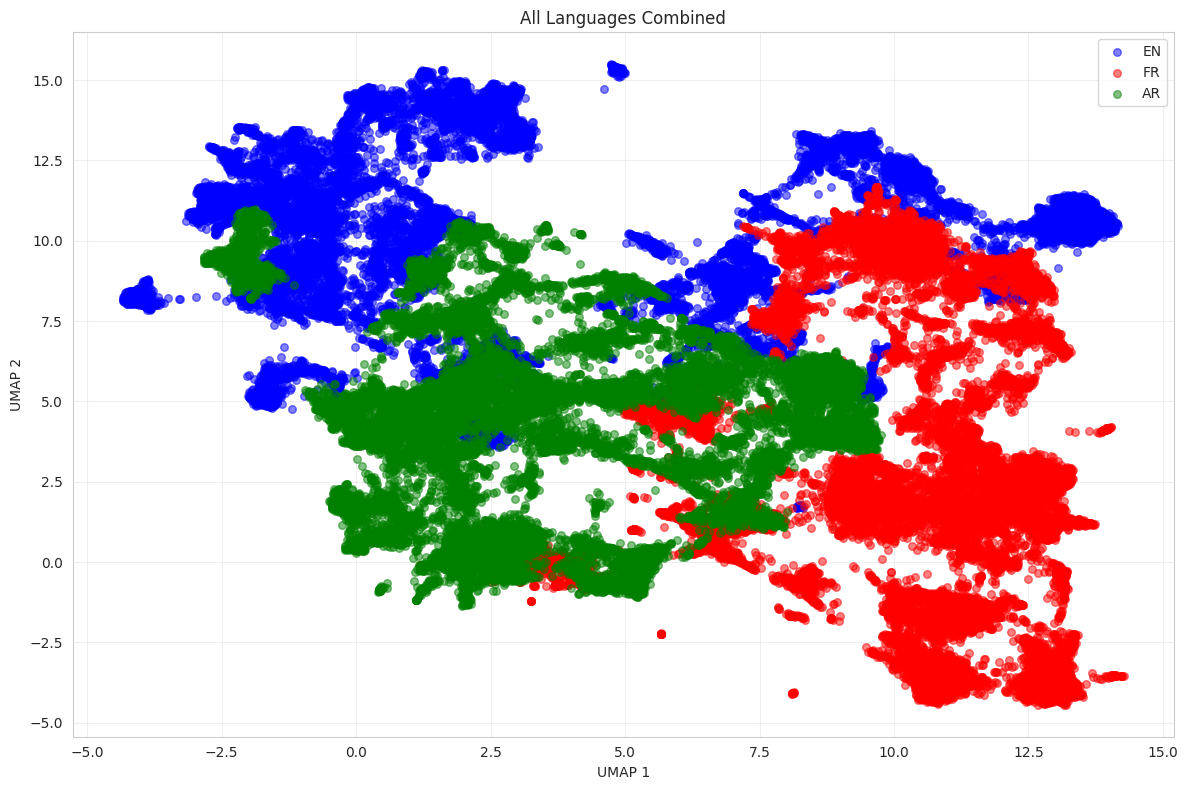

In [38]:
# Combine all embeddings for visualization
all_embeddings = []
all_labels = []

for lang in languages:
    emb_2d = embeddings_2d[lang]
    all_embeddings.append(emb_2d)
    all_labels.extend([lang] * len(emb_2d))

all_embeddings = np.vstack(all_embeddings)

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

lang_colors = {'en': 'blue', 'fr': 'red', 'ar': 'green'}
for lang in languages:
    mask = np.array([l == lang for l in all_labels])
    ax.scatter(all_embeddings[mask, 0], all_embeddings[mask, 1],
              c=lang_colors[lang], label=lang.upper(), alpha=0.5, s=30)

ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_title('All Languages Combined')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Compute Similarity Statistics

In [39]:
# Find entities that exist in all languages
common_entity_ids = set(embeddings['en']['entity_ids'])
for lang in languages[1:]:
    common_entity_ids = common_entity_ids.intersection(set(embeddings[lang]['entity_ids']))

common_entity_ids = sorted(list(common_entity_ids))

print(f"Entities with embeddings in all languages: {len(common_entity_ids)}")

Entities with embeddings in all languages: 26071


In [40]:
# For common entities, compute cross-language similarities
if len(common_entity_ids) > 0:
    # Get embeddings for common entities in each language
    common_embeddings = {}

    for lang in languages:
        entity_ids = embeddings[lang]['entity_ids']
        emb = embeddings[lang]['embeddings']

        # Find indices of common entities
        indices = [entity_ids.index(eid) for eid in common_entity_ids if eid in entity_ids]
        common_embeddings[lang] = emb[indices]

        print(f"{lang}: {len(indices)} common entities")

    # Compute pairwise similarities
    from sklearn.metrics.pairwise import cosine_similarity

    print("\n" + "="*60)
    print("Cross-Language Similarities (mean cosine similarity)")
    print("="*60)

    for i, lang1 in enumerate(languages):
        for lang2 in languages[i+1:]:
            # Compute pairwise similarities for same entities across languages
            similarities = []
            for idx in range(len(common_entity_ids)):
                sim = cosine_similarity(
                    common_embeddings[lang1][idx:idx+1],
                    common_embeddings[lang2][idx:idx+1]
                )[0, 0]
                similarities.append(sim)

            mean_sim = np.mean(similarities)
            std_sim = np.std(similarities)
            print(f"{lang1.upper()} <-> {lang2.upper()}: {mean_sim:.4f} ± {std_sim:.4f}")

en: 26071 common entities
fr: 26071 common entities
ar: 26071 common entities

Cross-Language Similarities (mean cosine similarity)
EN <-> FR: 0.8688 ± 0.0582
EN <-> AR: 0.8187 ± 0.0408
FR <-> AR: 0.8195 ± 0.0497


## 9. Summary Statistics

In [41]:
print("=" * 60)
print("EMBEDDING GENERATION SUMMARY")
print("=" * 60)

print(f"\nModel: {model_name}")
print(f"Total entities: {len(df)}")

print(f"\nEmbeddings generated:")
for lang in languages:
    n_emb = len(embeddings[lang]['entity_ids'])
    dim = embeddings[lang]['embeddings'].shape[1]
    print(f"  {lang.upper()}: {n_emb} entities × {dim} dimensions")

print(f"\nCache directory: {cache_dir}")
print(f"Cached files: {len(list(cache_dir.glob('*.pkl')))}")

print(f"\n✓ Ready for dimension reduction & clustering (notebook 03)")
print("=" * 60)

EMBEDDING GENERATION SUMMARY

Model: intfloat/multilingual-e5-large
Total entities: 26098

Embeddings generated:
  EN: 26098 entities × 1024 dimensions
  FR: 26095 entities × 1024 dimensions
  AR: 26074 entities × 1024 dimensions

Cache directory: ../data/embeddings
Cached files: 3

✓ Ready for dimension reduction & clustering (notebook 03)


In [ ]:
# Close database
db.conn.close()
print("Database connection closed")